# 03 - Logistic Regression và Decision Tree (SV3)

Tuning bằng `GridSearchCV(scoring="f1_macro")` với CV 5-fold chung của nhóm, trên tập đặc trưng **C** (đủ thông tin). Kết quả theo A/B/C cho RQ3 ở mục cuối chỉ để SV5 tham khảo.

Tập test không được dùng.

In [1]:
import os, sys, warnings
from pathlib import Path
os.chdir(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import config
from src.data import get_train_test
from src.evaluate import cross_validate_model, get_cv
from src.preprocessing import build_pipeline, build_preprocessor, get_feature_names, get_column_groups

sns.set_theme(style="whitegrid")
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
X_train, X_test, y_train, y_test = get_train_test("C")   # tập test KHÔNG dùng trong notebook này
print(X_train.shape, y_train.value_counts(normalize=True).round(3).to_dict())
import joblib
from sklearn.model_selection import GridSearchCV, validation_curve, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from src.evaluate import confusion, plot_confusion
config.MODELS_DIR.mkdir(exist_ok=True)
import tempfile; CACHE = tempfile.mkdtemp()  # cache bước tiền xử lý cho GridSearchCV

(3539, 36) {'Graduate': 0.499, 'Dropout': 0.321, 'Enrolled': 0.179}


## 1. Logistic Regression đa lớp

Lưới: `C`, `penalty` (L1/L2, solver `saga`), `class_weight`. Có chuẩn hóa (`scale=True`).

In [2]:
lr_grid = GridSearchCV(
    build_pipeline(LogisticRegression(solver="saga", max_iter=2000, tol=1e-3, random_state=42), "C", scale=True).set_params(memory=CACHE),
    param_grid={"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
                "clf__penalty": ["l1", "l2"],
                "clf__class_weight": [None, "balanced"]},
    scoring="f1_macro", cv=get_cv(), n_jobs=-1, refit=True, return_train_score=True)
lr_grid.fit(X_train, y_train)
lr_tab = pd.DataFrame(lr_grid.cv_results_)[["param_clf__C", "param_clf__penalty", "param_clf__class_weight",
         "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score")
lr_tab.round(4).to_csv(config.RESULTS_DIR / "lr_tuning.csv", index=False)
print("Best:", lr_grid.best_params_, "| CV Macro-F1 =", round(lr_grid.best_score_, 4))
lr_tab.head(8).round(4)

Best: {'clf__C': 0.3, 'clf__class_weight': 'balanced', 'clf__penalty': 'l2'} | CV Macro-F1 = 0.717


,param_clf__C,param_clf__penalty,param_clf__class_weight,mean_train_score,mean_test_score,std_test_score,rank_test_score
15,0.30,l2,balanced,0.7544,0.7170,0.0191,1
14,0.30,l1,balanced,0.7511,0.7161,0.0212,2
11,0.10,l2,balanced,0.7480,0.7160,0.0174,3
18,1.00,l1,balanced,0.7562,0.7140,0.0154,4
7,0.03,l2,balanced,0.7363,0.7134,0.0173,5
10,0.10,l1,balanced,0.7273,0.7128,0.0198,6
22,3.00,l1,balanced,0.7575,0.7120,0.0141,7
23,3.00,l2,balanced,0.7573,0.7115,0.0139,8


In [3]:
lr_best = lr_grid.best_estimator_
lr_res = cross_validate_model(lr_best, X_train, y_train, name="LogisticRegression", feature_set="C", log=False)
joblib.dump(lr_best, config.MODELS_DIR / "lr_best.joblib")
pd.Series(lr_res).drop(["model", "feature_set"]).astype(float).round(4)

f1_macro_mean             0.7170
f1_macro_std              0.0191
balanced_accuracy_mean    0.7246
balanced_accuracy_std     0.0198
accuracy_mean             0.7578
accuracy_std              0.0162
recall_dropout_mean       0.7361
recall_dropout_std        0.0228
f1_enrolled_mean          0.5305
f1_enrolled_std           0.0417
train_f1_macro_mean       0.7544
fit_time_mean             1.9750
dtype: float64

### Hệ số theo từng lớp (để diễn giải, RQ2)

Đặc trưng số đã chuẩn hóa nên độ lớn hệ số so sánh được tương đối. Hệ số dương = tăng xác suất của lớp đó (so với các lớp còn lại trong mô hình đa lớp softmax).

Hệ số = 0 ở cả 3 lớp: 0 / 123


,Dropout,Enrolled,Graduate,max_abs
Tuition fees up to date,-1.628,0.341,1.288,1.628
Curricular units 2nd sem (approved),-0.860,-0.697,1.557,1.557
Curricular units 1st sem (approved),-0.716,-0.396,1.113,1.113
Mother's occupation_0,0.707,-0.890,0.183,0.890
Course_171,-0.870,0.160,0.710,0.870
Curricular units 2nd sem (enrolled),0.609,0.222,-0.831,0.831
Course_9238,-0.330,-0.458,0.788,0.788
Father's occupation_infrequent_sklearn,-0.775,0.657,0.119,0.775
Course_9119,-0.026,0.775,-0.749,0.775
Course_9853,0.757,0.006,-0.763,0.763


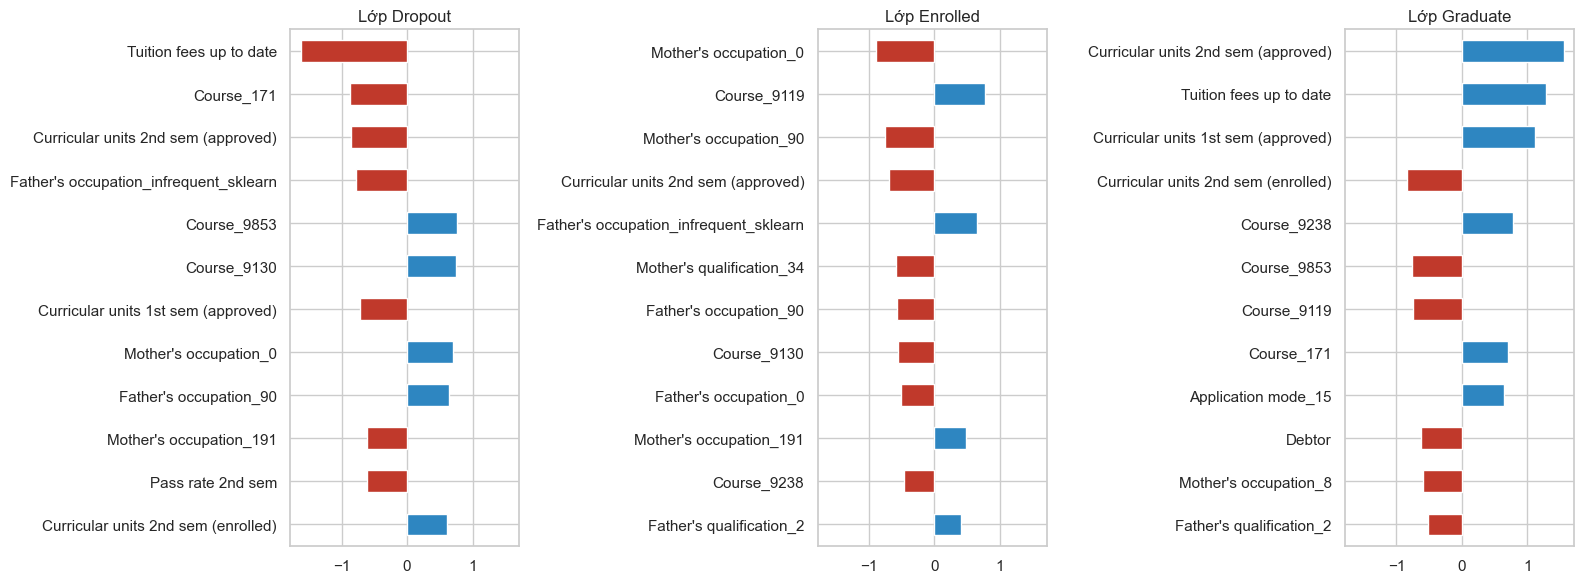

In [4]:
lr_fit = lr_best
names = get_feature_names(lr_fit)
coef = pd.DataFrame(lr_fit.named_steps["clf"].coef_.T, index=names, columns=lr_fit.named_steps["clf"].classes_)
coef["max_abs"] = coef.abs().max(axis=1)
coef = coef.sort_values("max_abs", ascending=False)
coef.round(4).to_csv(config.RESULTS_DIR / "lr_coefficients.csv")
print("Hệ số = 0 ở cả 3 lớp:", int((coef["max_abs"] == 0).sum()), "/", len(coef))
fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharex=True)
for ax, c in zip(axes, config.CLASSES):
    s = coef[c].reindex(coef[c].abs().sort_values(ascending=False).index).head(12)[::-1]
    s.plot.barh(ax=ax, color=["#c0392b" if v < 0 else "#2e86c1" for v in s]); ax.set_title(f"Lớp {c}")
fig.tight_layout(); fig.savefig(config.FIGURES_DIR / "03_lr_coef_by_class.png", dpi=200)
coef.head(10).round(3)

## 2. Decision Tree

Lưới: `max_depth`, `min_samples_leaf`, `criterion`, `ccp_alpha`. Không cần chuẩn hóa (`scale=False`).

In [5]:
dt_grid = GridSearchCV(
    build_pipeline(DecisionTreeClassifier(random_state=42), "C", scale=False).set_params(memory=CACHE),
    param_grid={"clf__max_depth": [3, 4, 5, 6, 8, 10, None],
                "clf__min_samples_leaf": [1, 5, 10, 20, 50],
                "clf__criterion": ["gini", "entropy"],
                "clf__ccp_alpha": [0.0, 0.0005, 0.001, 0.005]},
    scoring="f1_macro", cv=get_cv(), n_jobs=-1, refit=True, return_train_score=True)
dt_grid.fit(X_train, y_train)
dt_tab = pd.DataFrame(dt_grid.cv_results_)[["param_clf__max_depth", "param_clf__min_samples_leaf", "param_clf__criterion",
         "param_clf__ccp_alpha", "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score")
dt_tab.round(4).to_csv(config.RESULTS_DIR / "dt_tuning.csv", index=False)
print("Best:", dt_grid.best_params_, "| CV Macro-F1 =", round(dt_grid.best_score_, 4))
dt_tab.head(8).round(4)

Best: {'clf__ccp_alpha': 0.0, 'clf__criterion': 'entropy', 'clf__max_depth': 4, 'clf__min_samples_leaf': 10} | CV Macro-F1 = 0.6823


,param_clf__max_depth,param_clf__min_samples_leaf,param_clf__criterion,param_clf__ccp_alpha,mean_train_score,mean_test_score,std_test_score,rank_test_score
42,4,10,entropy,0.0000,0.6952,0.6823,0.0139,1
112,4,10,entropy,0.0005,0.6952,0.6823,0.0139,1
182,4,10,entropy,0.0010,0.6952,0.6823,0.0139,1
41,4,5,entropy,0.0000,0.6951,0.6808,0.0165,4
111,4,5,entropy,0.0005,0.6951,0.6808,0.0165,4
110,4,1,entropy,0.0005,0.6951,0.6808,0.0165,4
180,4,1,entropy,0.0010,0.6951,0.6808,0.0165,4
40,4,1,entropy,0.0000,0.6951,0.6808,0.0165,4


In [6]:
dt_best = dt_grid.best_estimator_
dt_res = cross_validate_model(dt_best, X_train, y_train, name="DecisionTree", feature_set="C", log=False)
joblib.dump(dt_best, config.MODELS_DIR / "dt_best.joblib")
pd.Series(dt_res).drop(["model", "feature_set"]).astype(float).round(4)

f1_macro_mean             0.6823
f1_macro_std              0.0139
balanced_accuracy_mean    0.6747
balanced_accuracy_std     0.0184
accuracy_mean             0.7482
accuracy_std              0.0097
recall_dropout_mean       0.6587
recall_dropout_std        0.0135
f1_enrolled_mean          0.4533
f1_enrolled_std           0.0415
train_f1_macro_mean       0.6952
fit_time_mean             0.1024
dtype: float64

### Overfit: train vs validation theo độ sâu

Các siêu tham số còn lại giữ như mô hình tốt nhất, chỉ đổi `max_depth`.

,max_depth,train,validation
0,2,0.5228,0.5218
1,3,0.6757,0.6666
2,4,0.6952,0.6823
3,5,0.7019,0.6728
4,6,0.7153,0.6768
5,8,0.7456,0.6765
6,10,0.7671,0.6611
7,14,0.7807,0.6444
8,20,0.7806,0.6443


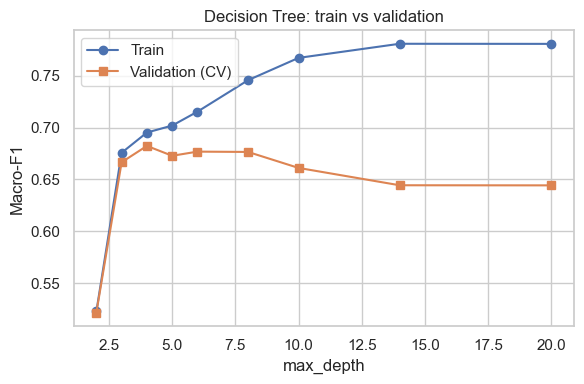

In [7]:
bp = {k.replace("clf__", ""): v for k, v in dt_grid.best_params_.items() if k != "clf__max_depth"}
depths = [2, 3, 4, 5, 6, 8, 10, 14, 20]
tr, va = validation_curve(build_pipeline(DecisionTreeClassifier(random_state=42, **bp), "C", scale=False),
                          X_train, y_train, param_name="clf__max_depth", param_range=depths,
                          cv=get_cv(), scoring="f1_macro", n_jobs=-1)
vc = pd.DataFrame({"max_depth": depths, "train": tr.mean(1), "validation": va.mean(1)}).round(4)
vc.to_csv(config.RESULTS_DIR / "dt_depth_curve.csv", index=False)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(depths, vc["train"], "o-", label="Train"); ax.plot(depths, vc["validation"], "s-", label="Validation (CV)")
ax.set_xlabel("max_depth"); ax.set_ylabel("Macro-F1"); ax.set_title("Decision Tree: train vs validation"); ax.legend()
fig.tight_layout(); fig.savefig(config.FIGURES_DIR / "03_dt_depth_curve.png", dpi=200)
vc

Pass rate 2nd sem                         0.7435
Curricular units 1st sem (enrolled)       0.0844
Tuition fees up to date                   0.0813
Pass rate 1st sem                         0.0370
GDP                                       0.0221
Curricular units 2nd sem (grade)          0.0145
Curricular units 2nd sem (evaluations)    0.0097
Admission grade                           0.0075
Marital Status_1                          0.0000
Marital Status_2                          0.0000
dtype: float64

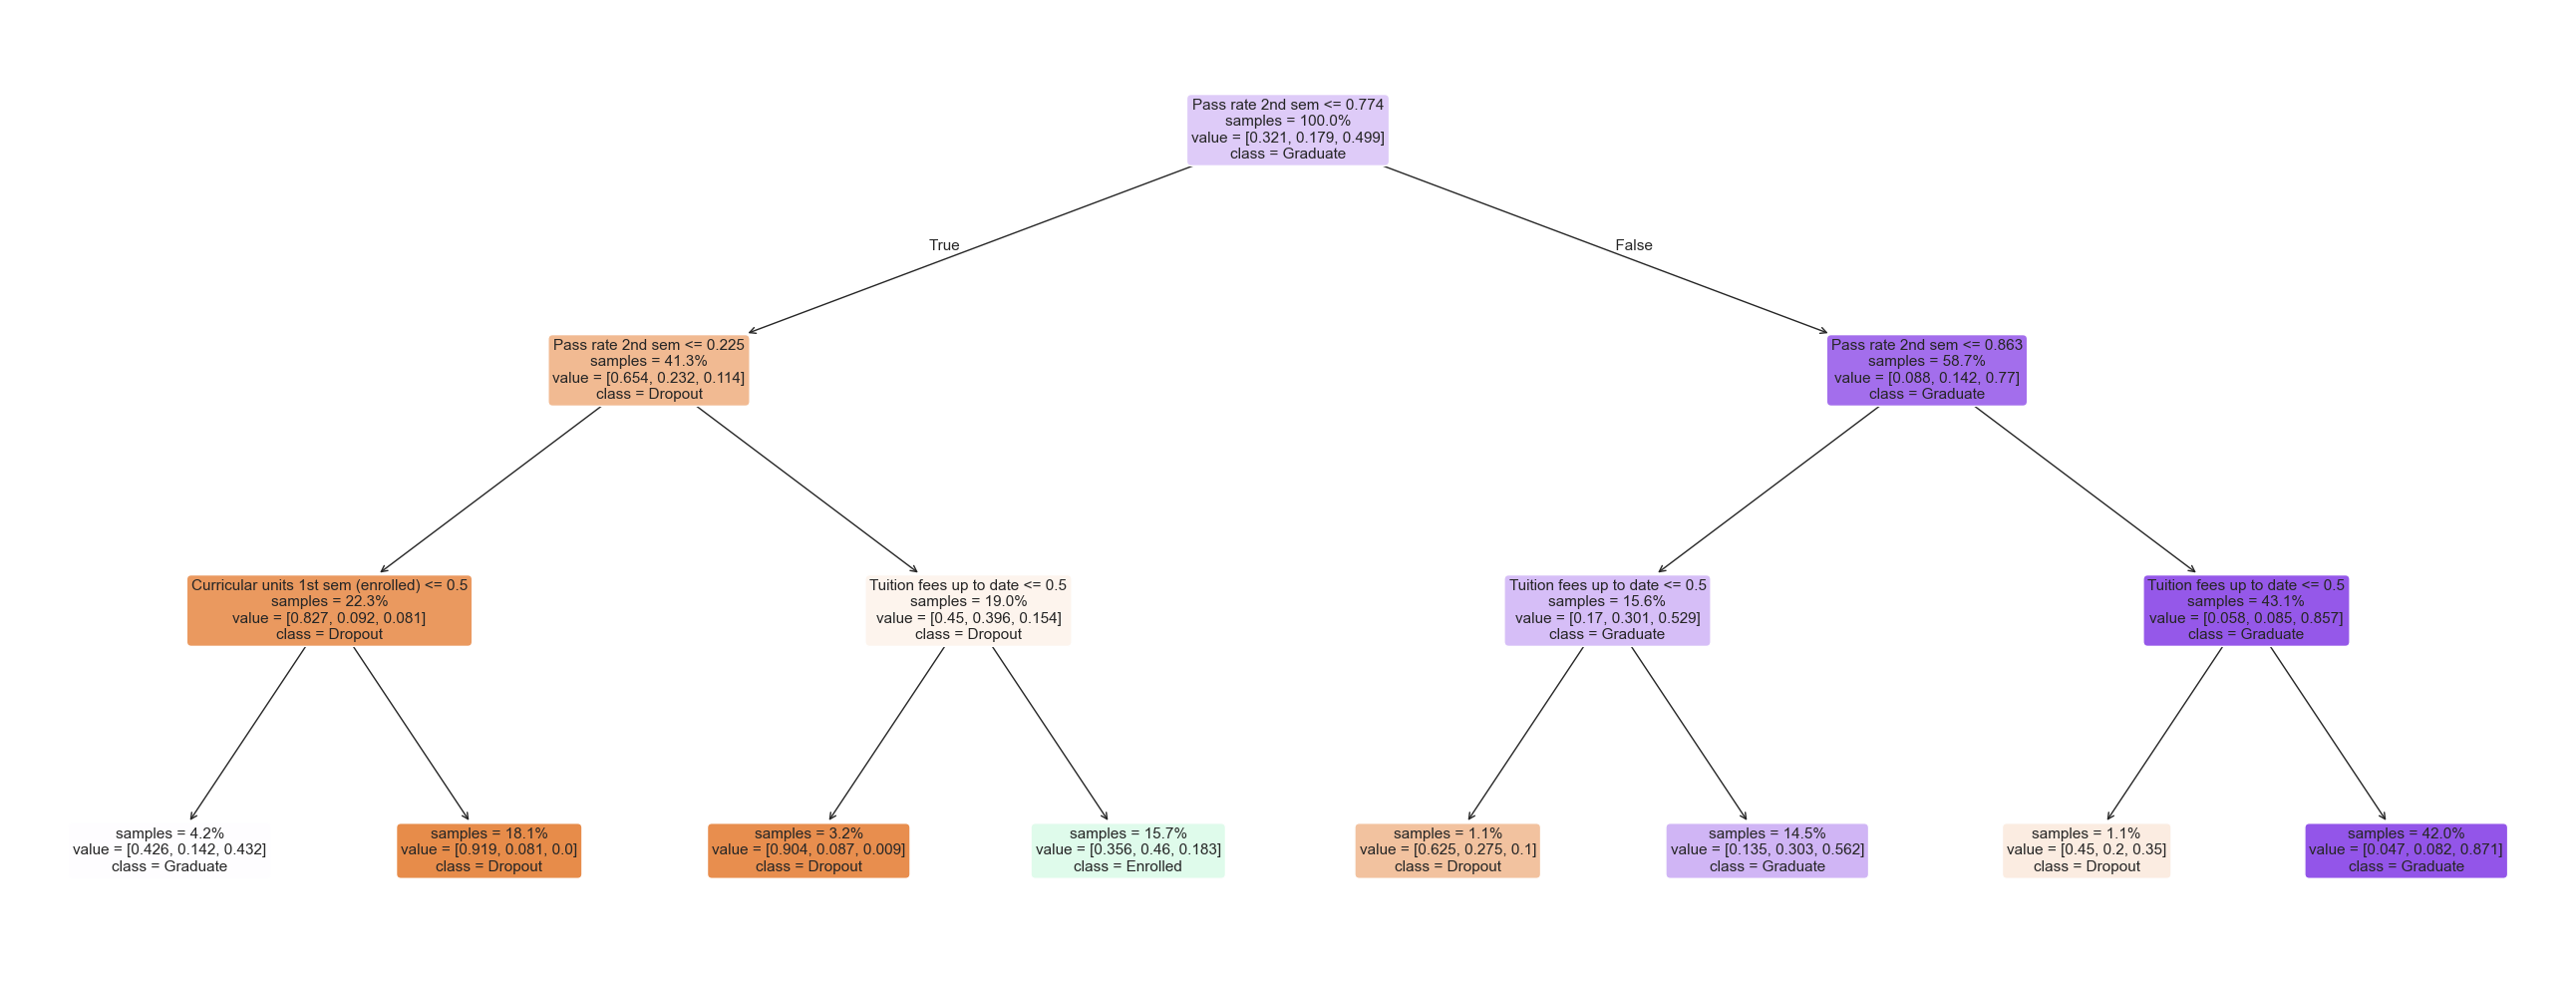

In [8]:
# Cây độ sâu 3 để trực quan hóa luật quyết định (chỉ minh họa, không thay mô hình tốt nhất)
bp3 = {k: v for k, v in bp.items() if k != "ccp_alpha"}
dt_vis = build_pipeline(DecisionTreeClassifier(max_depth=3, random_state=42, **bp3), "C", scale=False).fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(26, 10))
plot_tree(dt_vis.named_steps["clf"], feature_names=get_feature_names(dt_vis), class_names=list(dt_vis.named_steps["clf"].classes_),
          filled=True, rounded=True, fontsize=11, impurity=False, proportion=True, ax=ax)
fig.tight_layout(); fig.savefig(config.FIGURES_DIR / "03_dt_tree_depth3.png", dpi=200)

imp = pd.Series(dt_best.named_steps["clf"].feature_importances_, index=get_feature_names(dt_best)).sort_values(ascending=False)
imp.round(4).to_csv(config.RESULTS_DIR / "dt_feature_importance.csv", header=["importance"])
imp.head(10).round(4)

### Nhận xét train vs validation (overfit)

In [9]:
rows=[]
for n,r in [("LogisticRegression",lr_res),("DecisionTree",dt_res)]:
    gap=r["train_f1_macro_mean"]-r["f1_macro_mean"]
    rows.append({"model":n,"train_f1":round(r["train_f1_macro_mean"],4),"val_f1":round(r["f1_macro_mean"],4),"chenh_lech":round(gap,4),"val_std":round(r["f1_macro_std"],4)})
gap_tab=pd.DataFrame(rows); gap_tab.to_csv(config.RESULTS_DIR/"sv3_train_vs_val.csv",index=False)
dc=pd.read_csv(config.RESULTS_DIR/"dt_depth_curve.csv"); b=dc.loc[dc.validation.idxmax()]
print(gap_tab.to_string(index=False))
print(f"\nDT: validation cao nhất ở max_depth={int(b.max_depth)} (val={b.validation:.3f}); depth=20 train={dc.train.iloc[-1]:.3f} val={dc.validation.iloc[-1]:.3f} -> overfit khi cây quá sâu.")

             model  train_f1  val_f1  chenh_lech  val_std
LogisticRegression    0.7544  0.7170      0.0373   0.0191
      DecisionTree    0.6952  0.6823      0.0129   0.0139

DT: validation cao nhất ở max_depth=4 (val=0.682); depth=20 train=0.781 val=0.644 -> overfit khi cây quá sâu.


**Nhận xét:** chênh lệch train - validation của LR nhỏ (mô hình ổn định, ít overfit). Decision Tree cho thấy overfit rõ khi tăng độ sâu: train tiếp tục tăng còn validation giảm sau độ sâu tối ưu; vì vậy giữ cây nông (độ sâu 4) và dùng `min_samples_leaf`/`ccp_alpha` để hạn chế.

## 3. So sánh LR, DT và baseline (CV trên train)

In [10]:
base = pd.read_csv(config.RESULTS_DIR / "baseline_table.csv") if (config.RESULTS_DIR / "baseline_table.csv").exists() else pd.DataFrame()
cmp_ = pd.concat([base, pd.DataFrame([lr_res, dt_res])], ignore_index=True)
cols = ["model", "f1_macro_mean", "f1_macro_std", "train_f1_macro_mean", "balanced_accuracy_mean", "accuracy_mean", "recall_dropout_mean", "f1_enrolled_mean"]
cmp_ = cmp_[cols].round(4); cmp_.to_csv(config.RESULTS_DIR / "sv3_comparison_table.csv", index=False)
cmp_

,model,f1_macro_mean,f1_macro_std,train_f1_macro_mean,balanced_accuracy_mean,accuracy_mean,recall_dropout_mean,f1_enrolled_mean
0,Dummy(most_frequent),0.2220,0.0002,0.2220,0.3333,0.4993,0.0000,0.0000
1,Dummy(stratified),0.3383,0.0092,0.3305,0.3385,0.3919,0.3465,0.1745
2,LogisticRegression,0.7170,0.0191,0.7544,0.7246,0.7578,0.7361,0.5305
3,DecisionTree,0.6823,0.0139,0.6952,0.6747,0.7482,0.6587,0.4533


LR
               pred_Dropout  pred_Enrolled  pred_Graduate
true_Dropout            837            209             91
true_Enrolled            95            390            150
true_Graduate            76            236           1455

DT
               pred_Dropout  pred_Enrolled  pred_Graduate
true_Dropout            749            212            176
true_Enrolled            77            288            270
true_Graduate            32            124           1611



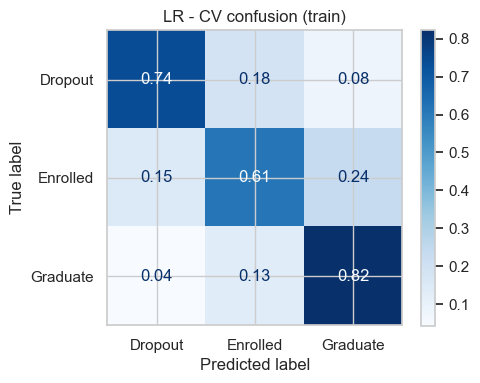

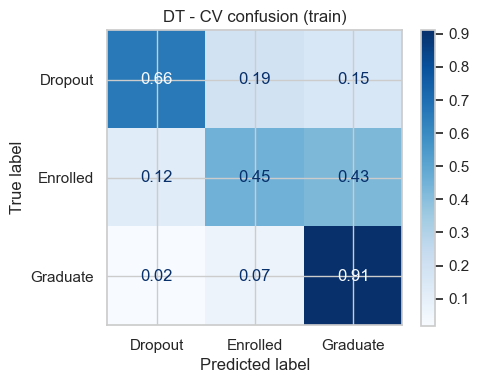

In [11]:
# Confusion matrix từ dự đoán CV (out-of-fold) - không dùng tập test
for name, m in [("LR", lr_best), ("DT", dt_best)]:
    pred = cross_val_predict(m, X_train, y_train, cv=get_cv(), n_jobs=-1)
    print(name); print(confusion(y_train, pred)); print()
    plot_confusion(y_train, pred, title=f"{name} - CV confusion (train)", save_as=f"03_{name.lower()}_cv_confusion.png")

## 3b. Nhận xét overfit (train vs validation)

In [12]:
gap = pd.DataFrame({"model": ["LogisticRegression", "DecisionTree"],
    "train_f1": [lr_res["train_f1_macro_mean"], dt_res["train_f1_macro_mean"]],
    "val_f1": [lr_res["f1_macro_mean"], dt_res["f1_macro_mean"]]})
gap["chenh_lech"] = (gap["train_f1"] - gap["val_f1"]).round(4)
print(gap.round(4).to_string(index=False))
print("\nDT theo độ sâu (siêu tham số khác giữ như mô hình tốt nhất):")
print(vc.assign(chenh_lech=(vc["train"] - vc["validation"]).round(4)).to_string(index=False))

             model  train_f1  val_f1  chenh_lech
LogisticRegression    0.7544  0.7170      0.0373
      DecisionTree    0.6952  0.6823      0.0129

DT theo độ sâu (siêu tham số khác giữ như mô hình tốt nhất):
 max_depth  train  validation  chenh_lech
         2 0.5228      0.5218      0.0010
         3 0.6757      0.6666      0.0091
         4 0.6952      0.6823      0.0129
         5 0.7019      0.6728      0.0291
         6 0.7153      0.6768      0.0385
         8 0.7456      0.6765      0.0691
        10 0.7671      0.6611      0.1060
        14 0.7807      0.6444      0.1363
        20 0.7806      0.6443      0.1363


**Cách đọc:** chênh lệch train - validation nhỏ nghĩa là mô hình khái quát tốt; cây càng sâu thì train càng tăng còn validation đứng yên hoặc giảm -> overfit. Mô hình được chọn theo validation (CV), không theo train.

## 3c. Metadata cho bàn giao (Quốc) và hàm dự đoán

In [13]:
import json, platform, sklearn
meta = {
    "feature_set": "C", "seed": config.RANDOM_STATE, "n_splits": config.N_SPLITS, "scoring": "f1_macro",
    "classes": list(lr_best.named_steps["clf"].classes_),
    "libs": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
             "pandas": pd.__version__, "numpy": np.__version__},
    "models": {
        "lr": {"file": "models/lr_best.joblib", "best_params": {k: (None if v is None else v) for k, v in lr_grid.best_params_.items()},
               "cv_f1_macro": round(lr_res["f1_macro_mean"], 4), "cv_std": round(lr_res["f1_macro_std"], 4)},
        "dt": {"file": "models/dt_best.joblib", "best_params": {k: (None if v is None else v) for k, v in dt_grid.best_params_.items()},
               "cv_f1_macro": round(dt_res["f1_macro_mean"], 4), "cv_std": round(dt_res["f1_macro_std"], 4)},
    },
    "input_columns": list(X_train.columns),
    "binary_cols": config.BINARY_COLS,
    "categorical_cols": config.CATEGORICAL_COLS,
    "numeric_ranges": {c: [float(X_train[c].min()), float(X_train[c].max())]
                       for c in X_train.columns if c not in config.CATEGORICAL_COLS},
    "known_categories": {c: sorted(int(v) for v in X_train[c].unique()) for c in config.CATEGORICAL_COLS},
    "note": "Tuning chỉ dùng train + CV 5-fold; tập test không dùng.",
}
with open(config.MODELS_DIR / "sv3_metadata.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2, default=str)
print("Đã lưu models/sv3_metadata.json")
print(json.dumps(meta["models"], ensure_ascii=False, indent=1, default=str))

Đã lưu models/sv3_metadata.json
{
 "lr": {
  "file": "models/lr_best.joblib",
  "best_params": {
   "clf__C": 0.3,
   "clf__class_weight": "balanced",
   "clf__penalty": "l2"
  },
  "cv_f1_macro": 0.717,
  "cv_std": 0.0191
 },
 "dt": {
  "file": "models/dt_best.joblib",
  "best_params": {
   "clf__ccp_alpha": 0.0,
   "clf__criterion": "entropy",
   "clf__max_depth": 4,
   "clf__min_samples_leaf": 10
  },
  "cv_f1_macro": 0.6823,
  "cv_std": 0.0139
 }
}


## 4. Tham khảo cho RQ3: cùng siêu tham số, tập đặc trưng A/B/C

Chỉ là bảng nhanh của SV3 (siêu tham số tune trên tập C). SV5 chạy thí nghiệm A/B/C chính thức.

In [14]:
from sklearn.base import clone
rows = []
lr_p = {k.replace("clf__", ""): v for k, v in lr_grid.best_params_.items()}
dt_p = {k.replace("clf__", ""): v for k, v in dt_grid.best_params_.items()}
for fs in "ABC":
    Xa, _, ya, _ = get_train_test(fs)
    for name, est, sc in [("LogisticRegression", LogisticRegression(solver="saga", max_iter=2000, tol=1e-3, random_state=42, **lr_p), True),
                          ("DecisionTree", DecisionTreeClassifier(random_state=42, **dt_p), False)]:
        rows.append(cross_validate_model(build_pipeline(est, fs, sc), Xa, ya, name=name, feature_set=fs, log=False))
abc = pd.DataFrame(rows)[["model", "feature_set", "f1_macro_mean", "f1_macro_std", "recall_dropout_mean", "f1_enrolled_mean"]].round(4)
abc.to_csv(config.RESULTS_DIR / "sv3_abc_lr_dt.csv", index=False)
abc

,model,feature_set,f1_macro_mean,f1_macro_std,recall_dropout_mean,f1_enrolled_mean
0,LogisticRegression,A,0.5751,0.0208,0.5883,0.3996
1,DecisionTree,A,0.4616,0.0180,0.6006,0.0646
2,LogisticRegression,B,0.6810,0.0207,0.7036,0.4856
3,DecisionTree,B,0.6254,0.0139,0.6710,0.3164
4,LogisticRegression,C,0.7170,0.0191,0.7361,0.5305
5,DecisionTree,C,0.6823,0.0139,0.6587,0.4533
